# Predictions of interactions with SteadierCom for gut microbiome

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kendalltau

import sys

sys.path.append("../functions/")

from analysis.steady_state_flux import steadiercom_samples_plotting
from analysis.compare_auxotrophies import processing,plotting
from analysis.abundance_analysis import plotting as plotting_abundance
from analysis.abundance_analysis import co_growth

import data.guillen2021 as data


In [2]:
%load_ext autoreload
%autoreload 2

## Load data

#### Simulation results

In [3]:
simulation_dict = data.load_steadystate_simulation_results()


[INFO] Loading simulation results for Guillen2021 study for smetana, steadycom, and steadiercom.
[INFO] _process_simulation_results cleans up namespace for the simulation results.


#### Experimental data

In [4]:
experimental_abundance = data.load_experimental_abundance()

In [5]:
exp_abundance_replicas = data.load_experimental_abundance_replicas(experimental_abundance)

In [6]:
metclass2color_dict = {"carbohydrate derivatives":"#DEFD3C",  # carbohydrates and derivatives   e5fa79
            "amino acids and derivatives":"#ddaa7b",  # amino acids
            "nucleotides and derivatives":"#fbdc5d",  # nucleosides
            "oligosaccharides":"#8BBDAA",  # oligosaccharides #"#a7dfb6"
            "oligopeptides":"#FFD19B",  # oligopeptides 
            "simple sugars":"#9BF276",  # simple sugars   bfffa4
            "urea and urea derivatives":"#FFFFBA",  # urea 
            "gases":"#b1fbf6",  # gasses
            "B-vitamins":"#6F7FB0",  # B-vitamins #adb0e8
            "fatty acids":"#ffd1fd",   # fatty acids
            "carboxylic acids and anions":"#EB857E",  # carboxylic acids FFB3BA
            "alcohols and aldehydes":"#C3BBF3",  # alcohols and aldehydes 
            "lipids":"#8FCFFF", # phospholipids    
            "cofactors":"#FF85A1",
            "other":"#eaeaea"
            }

met_chebi_class = pd.read_csv("../data/met_chebi_class.tsv",sep="\t",index_col=0)
met_chebi_class["self defined super class"] = met_chebi_class["self defined super class"].map(lambda x: x if x in metclass2color_dict.keys() else "other")
super_class_map = met_chebi_class["self defined super class"].to_dict()


member2color_dict = {
                    'mutant_bioC':"#254094",
                    'mutant_bioF': "#2E51BB",
                    'mutant_bioH': "#94ABEF", 
                    'mutant_cysW':"#38761d",
                    'mutant_icd': "#E8C84B",
                    'mutant_panD': "#A53450",
                    'mutant_panZ': "#EC6889"
                    }

## Interactions (flux) - SteadyCom vs SteadierCom


#### Fixed growth and abundance
*Description*: bar plots and circos plots

*Main target*
- These plots are made for illustrating the SteadierCom predictions of the steady-state metabolic phenotype.
- Show difference between SteadyCom and SteadierCom: How relative abundance affects predicted in mass flux between members

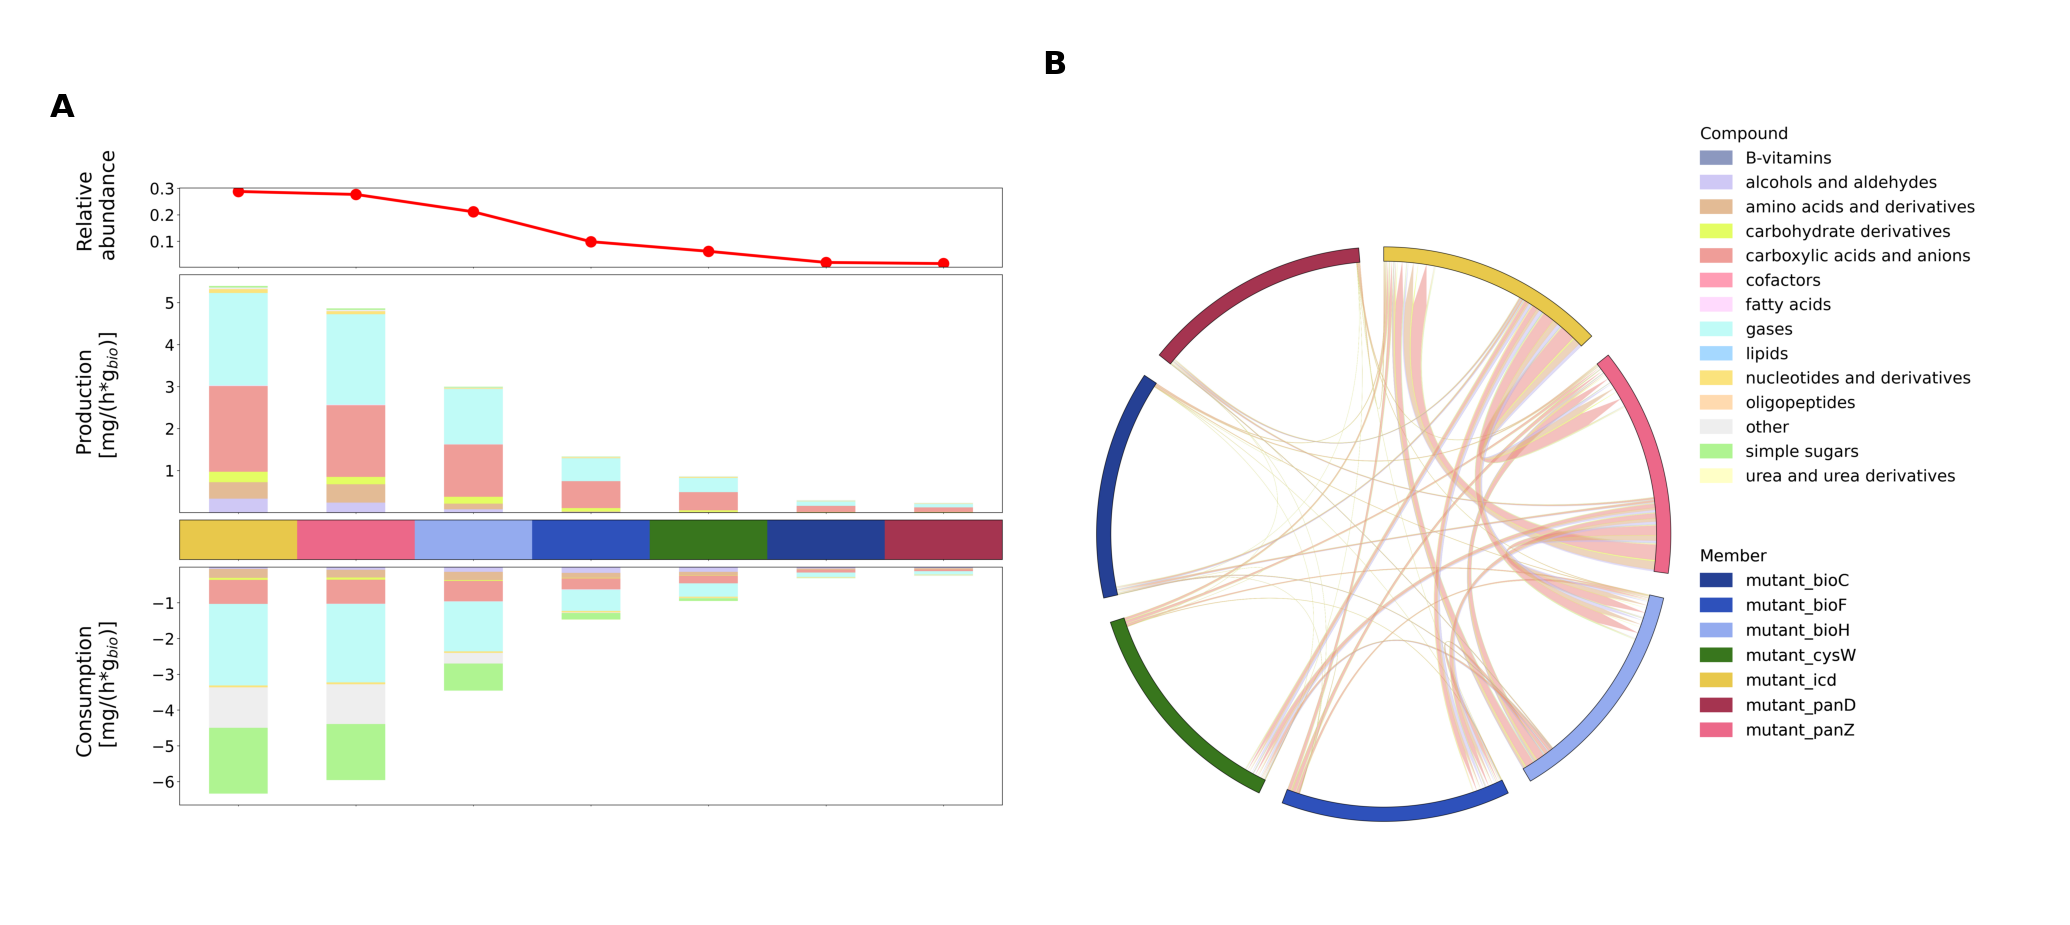

In [7]:
sim_results = simulation_dict["steadiercom"]["SteadierCom - Fixed growth & abundance"].copy()
sim_results["super_class"] = sim_results["compound"].map(super_class_map)

steadiercom_samples_plotting.combined_figure(sim_results,experimental_abundance,member2color_dict,"Ecoli_mutants",path = "../figures/circos/guillen2021/",move_legend=0)

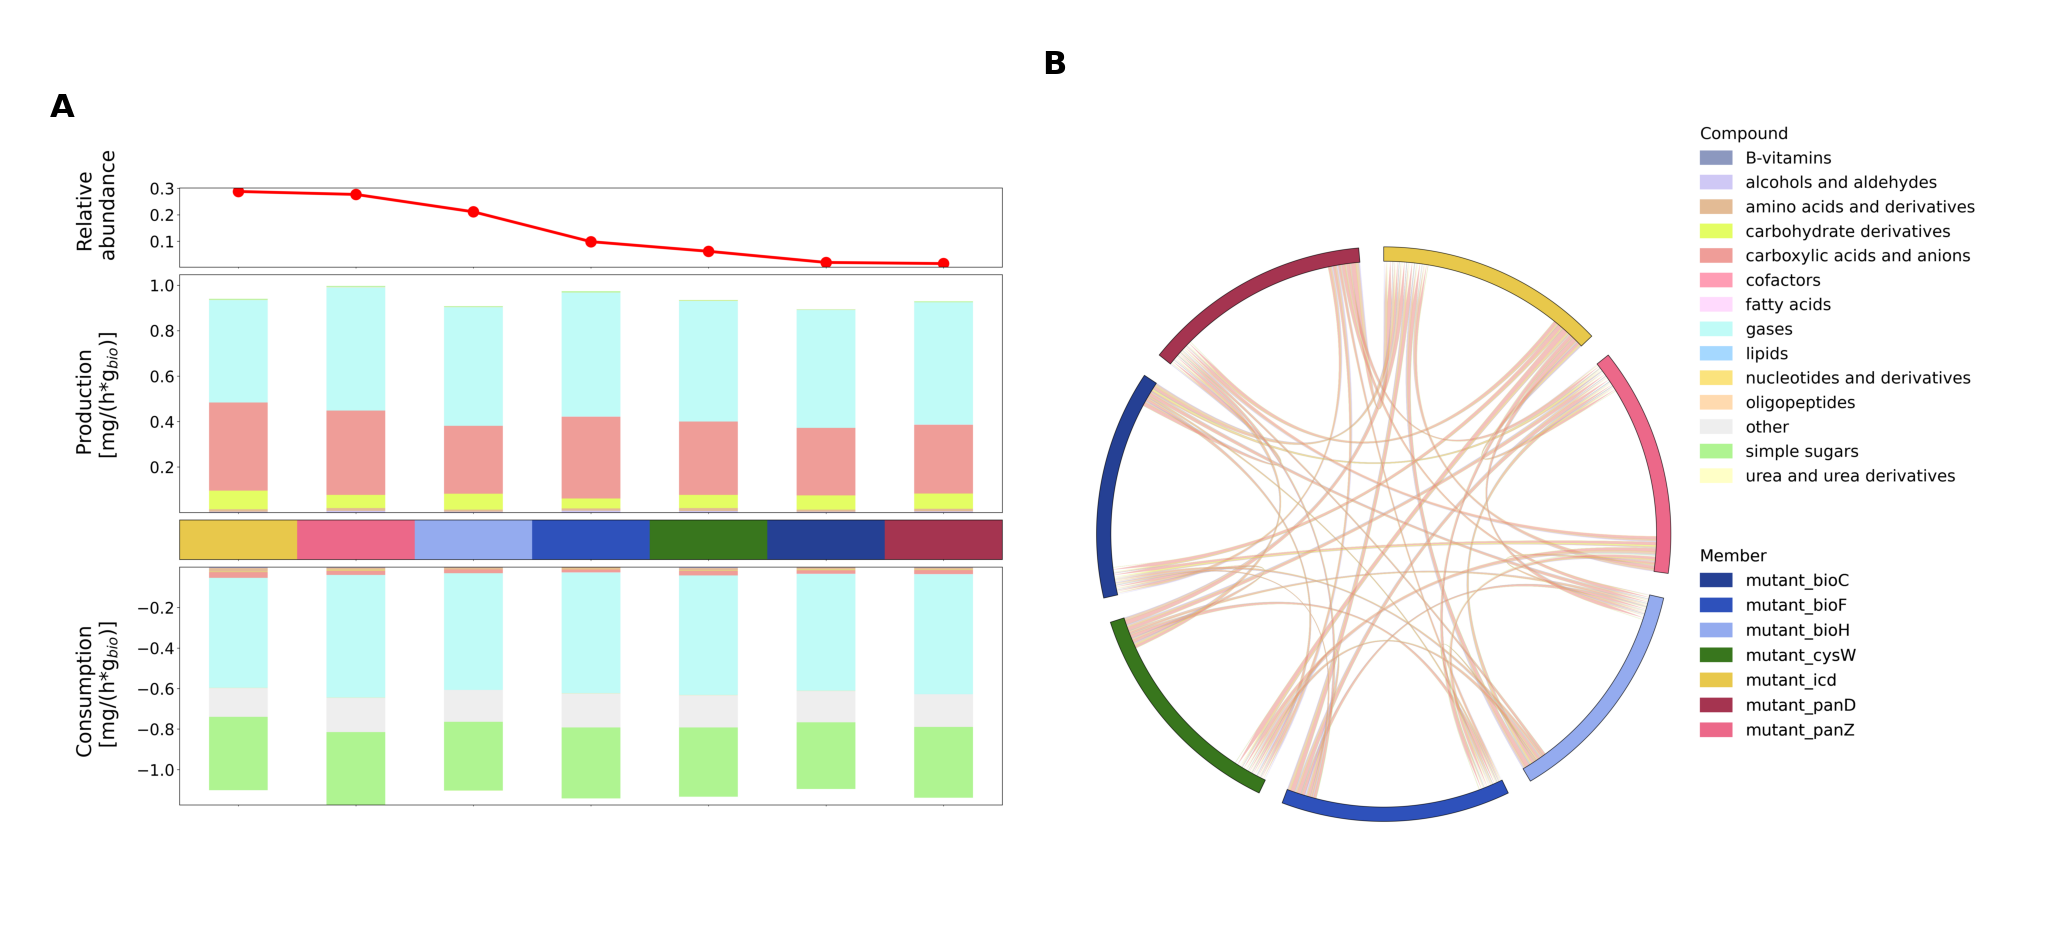

In [8]:
sim_results = simulation_dict["steadiercom"]["SteadierCom - Fixed growth"].copy()
sim_results["super_class"] = sim_results["compound"].map(super_class_map)
steadiercom_samples_plotting.combined_figure(sim_results,experimental_abundance,member2color_dict,"Ecoli_mutants",path = "../figures/circos/guillen2021/",move_legend=0)

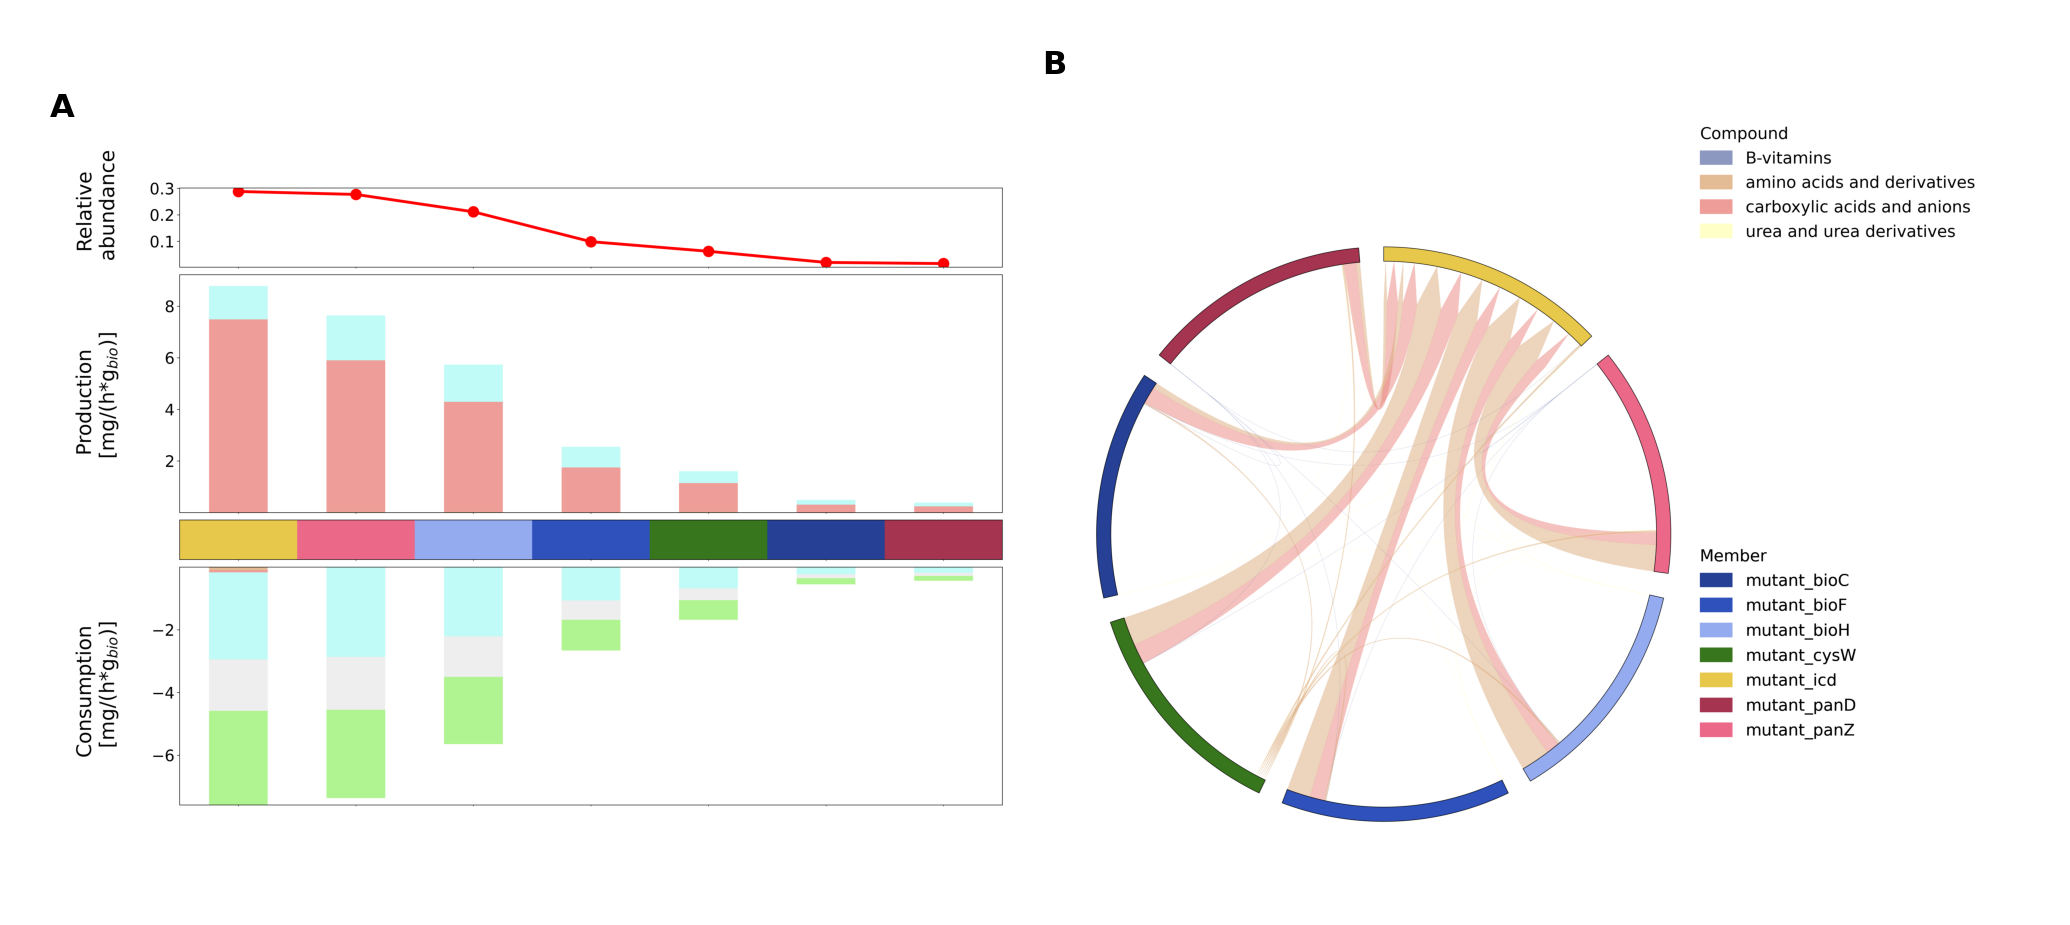

In [9]:
sim_results = simulation_dict["steadiercom"]["SteadierCom - Fixed abundance"].copy()
sim_results["super_class"] = sim_results["compound"].map(super_class_map)
steadiercom_samples_plotting.combined_figure(sim_results,experimental_abundance,member2color_dict,"Ecoli_mutants",path = "../figures/circos/guillen2021/",move_legend=0)

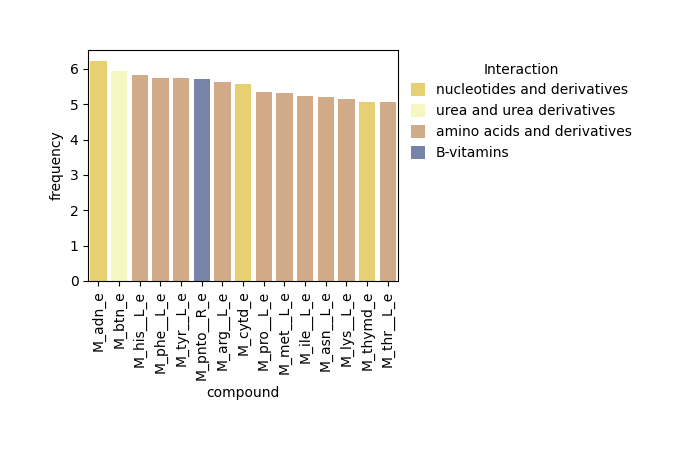

In [10]:
sim_results = simulation_dict["steadiercom"]["SteadierCom - Fixed growth & abundance"].copy()
sim_results["super_class"] = sim_results["compound"].map(super_class_map)

sim_results["mass_rate*frequency"] = sim_results.mass_rate*sim_results.frequency 
sim_inter_res = sim_results.query("receiver != 'environment' & donor != 'environment'")

df = (
    sim_inter_res
    .groupby(by=["super_class","compound"])["frequency"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
    )

fig,ax = plt.subplots(1,1,figsize=(4,3))
sns.barplot(df.head(15),x="compound",y="frequency",hue="super_class",palette=metclass2color_dict,ax=ax)

ax.tick_params(axis='x', rotation=90)

sns.move_legend(ax, "upper left",title="Interaction" ,bbox_to_anchor=(1.0, 1.0),)

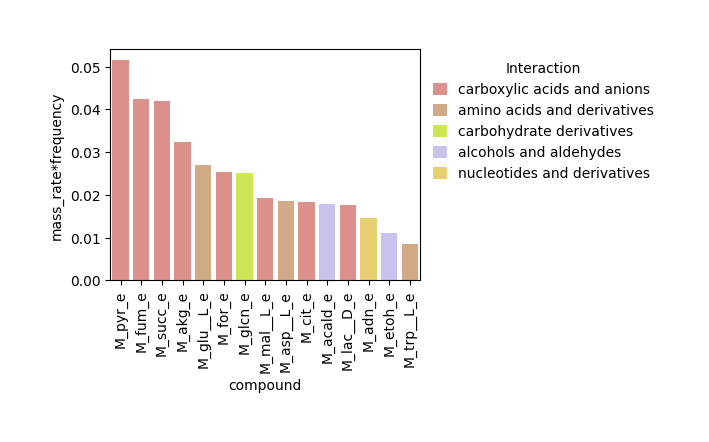

In [11]:
df = (
    sim_inter_res
    .groupby(by=["super_class","compound"])["mass_rate*frequency"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
    )

fig,ax = plt.subplots(1,1,figsize=(4,3))
sns.barplot(df.head(15),x="compound",y="mass_rate*frequency",hue="super_class",palette=metclass2color_dict,ax=ax)

ax.tick_params(axis='x', rotation=90)

sns.move_legend(ax, "upper left",title="Interaction" ,bbox_to_anchor=(1.0, 1.0),)

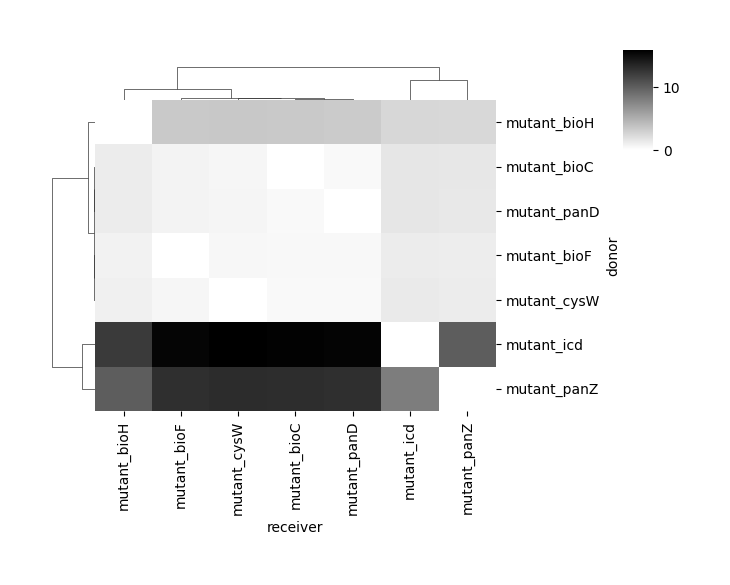

In [12]:
df = (
    sim_inter_res
    .groupby(by=["donor","receiver"])["frequency"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
    )
df2 = df.pivot_table(index=["receiver"],columns=["donor"],values="frequency").fillna(0)

sns.clustermap(df2.T,cmap="binary",method="ward",figsize=(6,5),dendrogram_ratio=0.1,cbar_pos=(0.98,0.8,0.05,0.2),)

### SteadierCom vs SteadyCom: Proteome constraints constrain the metabolic fluxes 
*Description*: Scatter plot of aggregate fluxes in SteadierCom and SteadyCom

*Main target*: Show how the fluxes are more constrained in SteadierCom

## Interactions (frequency) - SMETANA vs SteadierCom

*Description*: Compare with experimental results?? (For the flux prediction we don't really have experimental data for comparison, but here we kindoff do)

*Main target*: Show the difference between predicted important reactions in SMETANA and SteadierCom - for SteadierCom focus on frequency

In [13]:

smetana_results = simulation_dict["smetana"]["SMETANA"].copy()
steadiercom_results = simulation_dict["steadiercom"]["SteadierCom - Fixed growth & abundance"].copy()

merged_sim = processing.merge_smetana_steadiercom_triplets(smetana_results,steadiercom_results,super_class_map)
merged_sim = processing.add_auxotrophies_to_df(merged_sim)


### Per compound-class analysis: donor-compound-receiver (Triplets)

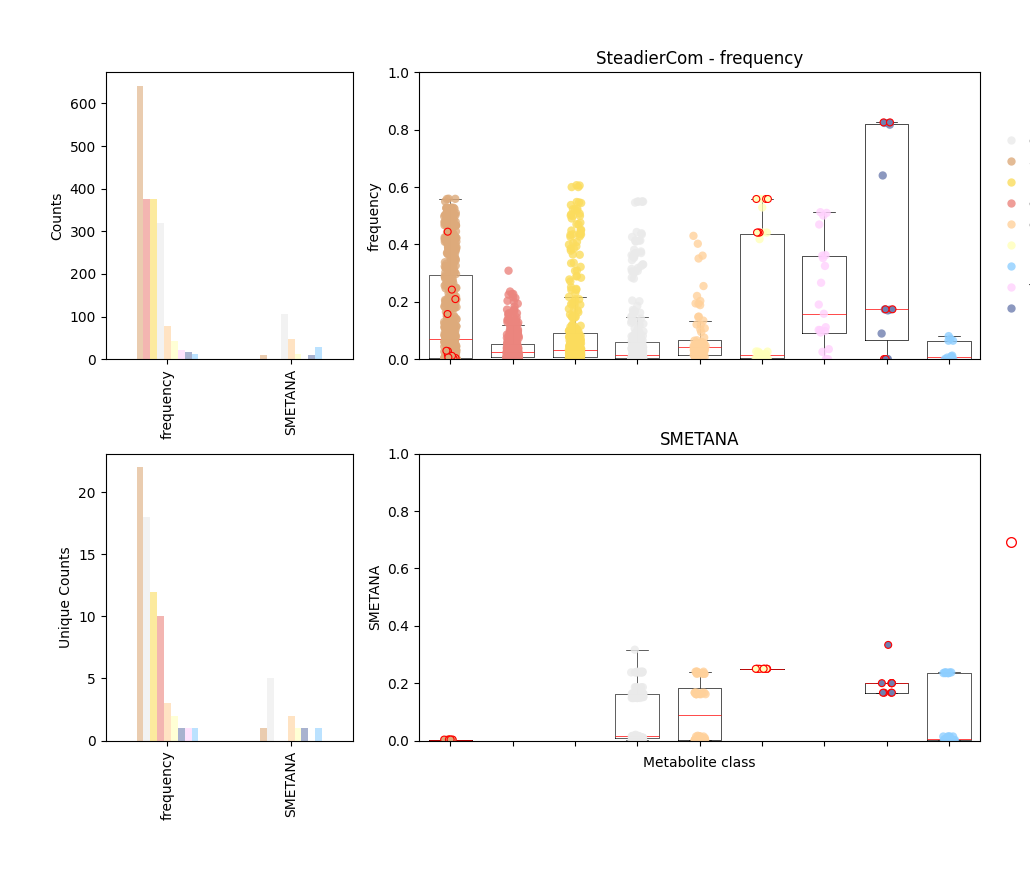

In [14]:
fig,(ax1a,ax1b,ax2,ax3) = plotting.plot_triplet_violin(merged_sim,metclass2color_dict)

### Per compound-class analysis: donor-compound-receiver (Triplets)

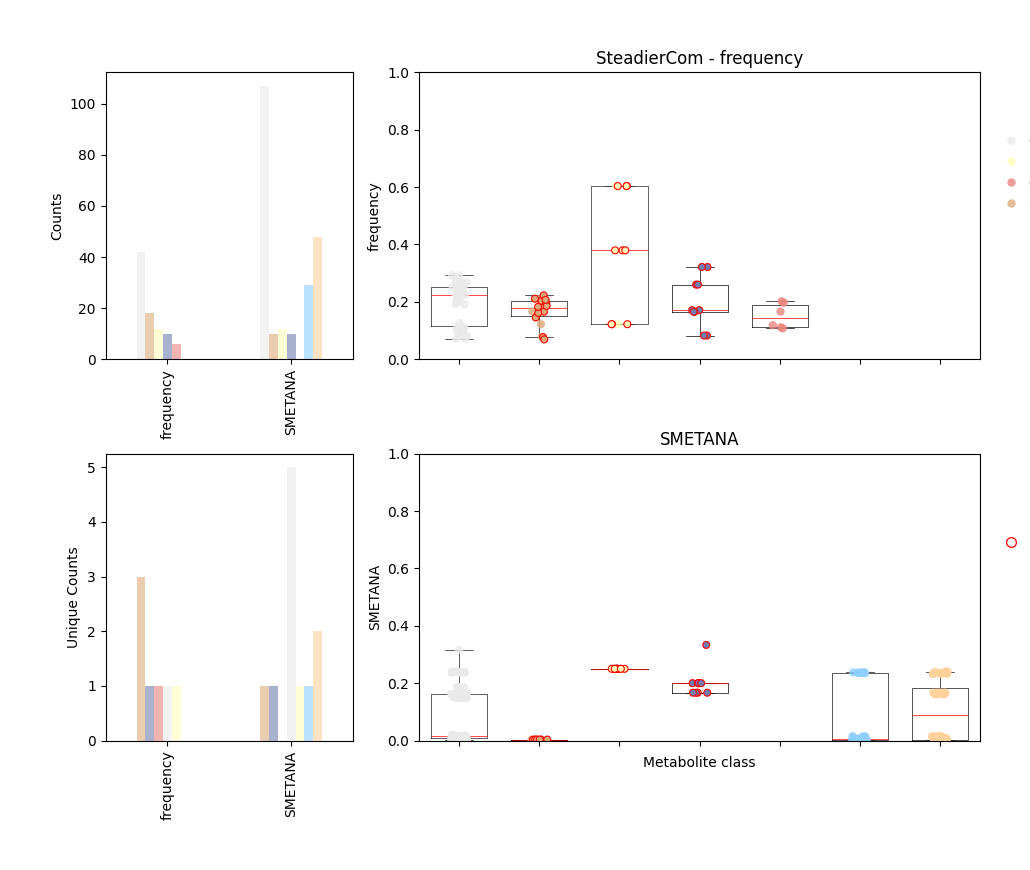

In [15]:

smetana_results = simulation_dict["smetana"]["SMETANA"].copy()
steadiercom_results = simulation_dict["steadiercom"]["SteadierCom - Fixed abundance"].copy()

merged_sim = processing.merge_smetana_steadiercom_triplets(smetana_results,steadiercom_results,super_class_map)
merged_sim = processing.add_auxotrophies_to_df(merged_sim)

fig,(ax1a,ax1b,ax2,ax3) = plotting.plot_triplet_violin(merged_sim,metclass2color_dict)

### Scatterplots for donor-compound-receiver

In [16]:
merged_sim = processing.merge_smetana_steadiercom_triplets(smetana_results,steadiercom_results,super_class_map)
merged_sim = processing.add_auxotrophies_to_df(merged_sim)

In [17]:

df = (
    merged_sim
    .query("expected_auxotrophy")
    .merge(experimental_abundance,
           left_on="donor",
           right_on="member",
           how="inner")
    .drop(["community_y","member"],axis=1)
    )

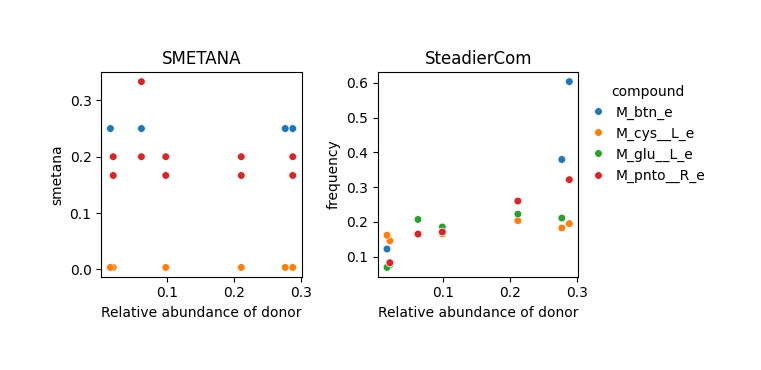

In [18]:
fig,axs = plt.subplots(1,2,figsize=(7,3))
legend=False
for ax,metric,method in zip(axs,["smetana","frequency"],["SMETANA","SteadierCom"]):
    ax =sns.scatterplot(df,x="relative_abundance",y=metric,hue="compound",s=30,ax=ax,legend=legend)
    ax.set_xlabel("Relative abundance of donor")
    legend=True
    ax.set_title(method)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()

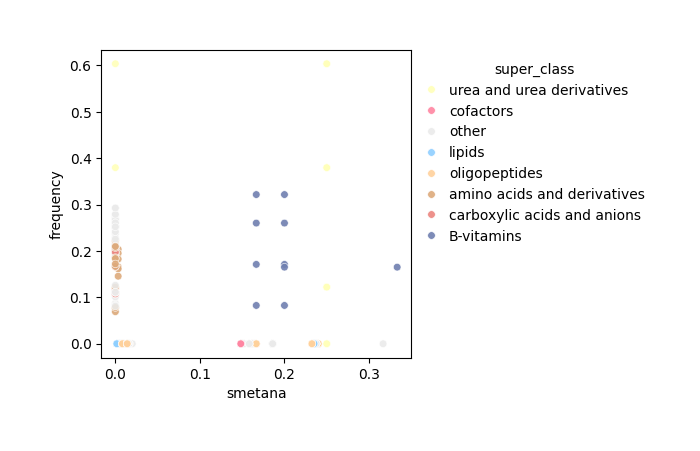

In [19]:
plot_df = merged_sim.fillna(0)

fig,ax = plt.subplots(1,1,figsize=(4,4))
ax = sns.scatterplot(plot_df,
                     x="smetana",
                     y="frequency",
                     hue="super_class", 
                     palette=metclass2color_dict,
                     alpha=0.9,
                     s=30,
                     legend=True,
                     ax=ax
                     )

sns.move_legend(ax, "upper left", bbox_to_anchor=(1.0, 1.0))

# Abundance

### SteadierCom

**Load and process data**

In [20]:
# Load experimental results
exp_abundance_df_reshaped = experimental_abundance.copy()


In [21]:
steadiercom_abundance_df, steadycom_abundance_reshaped = data.load_simulated_abundance()

**Plot**

/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom/lib/python3.10/site-packages/matplotlib/cbook.py:1709: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom/lib/python3.10/site-packages/matplotlib/cbook.py:1709: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom/lib/python3.10/site-packages/matplotlib/cbook.py:1709: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)
/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom/lib/python3.10/site-packages/matplotlib/cbook.py:1709: FutureWarning: Calling float on a single element Se

Text(0, 0.5, 'Simulated relative abundance')

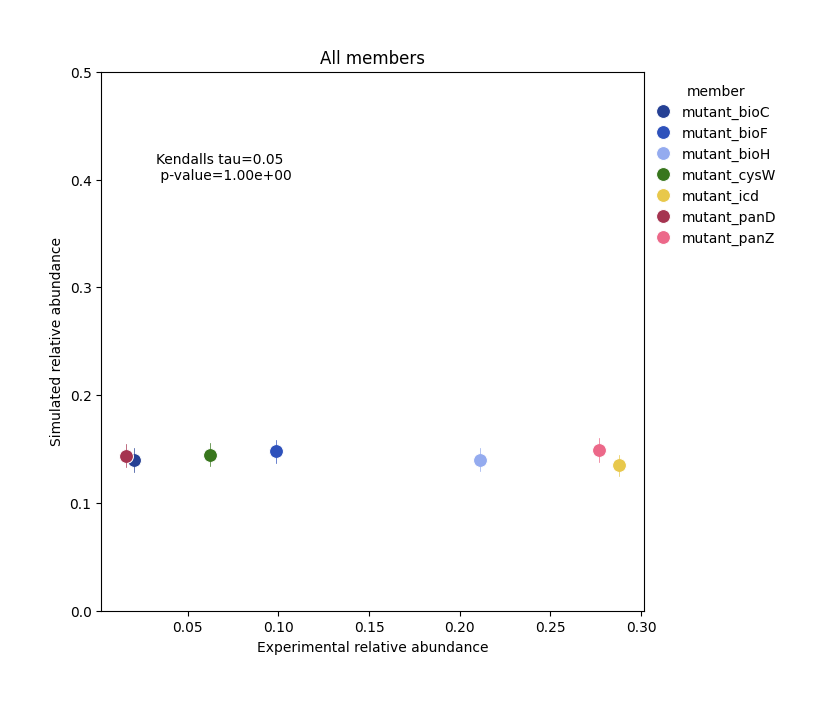

In [22]:
# Merge simulated and experimental data
joined_spec = pd.merge(steadiercom_abundance_df, exp_abundance_df_reshaped, on=["community","member"], suffixes=("_sim","_exp"))
fig, ax = plt.subplots(figsize=(7, 7))

plotting_abundance.plot_scatter_steadiercom(joined_spec,
                               ax,
                               "All members",
                               member_colors=member2color_dict,
                               legend=True)
sns.move_legend(ax, 
                "upper left",
                bbox_to_anchor=(1.0, 1.0)
                )
ax.set_ylim(0,0.5)
ax.set_xlabel("Experimental relative abundance")
ax.set_ylabel("Simulated relative abundance")

### SteadyCom

**Load and process data**

Text(0, 0.5, 'Simulated relative abundance')

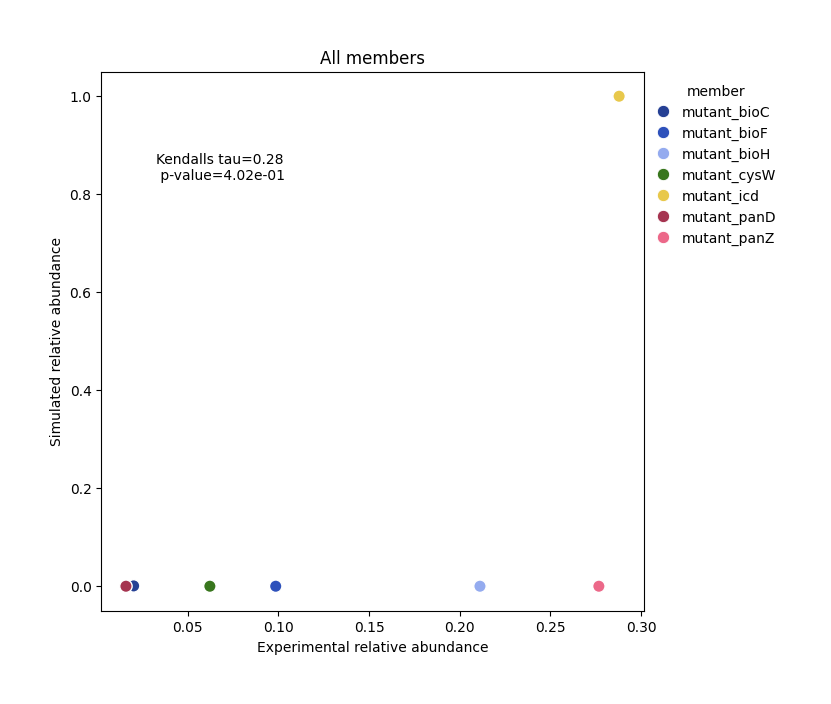

In [23]:

# Merge simulated and experimental data
joined_spec = pd.merge(steadycom_abundance_reshaped, exp_abundance_df_reshaped, on=["community","member"], suffixes=("_sim","_exp"))
fig, ax = plt.subplots(figsize=(7, 7))

plotting_abundance.plot_scatter_steadycom(joined_spec,
                               ax,
                               "All members",
                               member_colors=member2color_dict,
                               legend=True)
sns.move_legend(ax, 
                "upper left",
                bbox_to_anchor=(1.0, 1.0),
                
                )

ax.set_xlabel("Experimental relative abundance")
ax.set_ylabel("Simulated relative abundance")

[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.


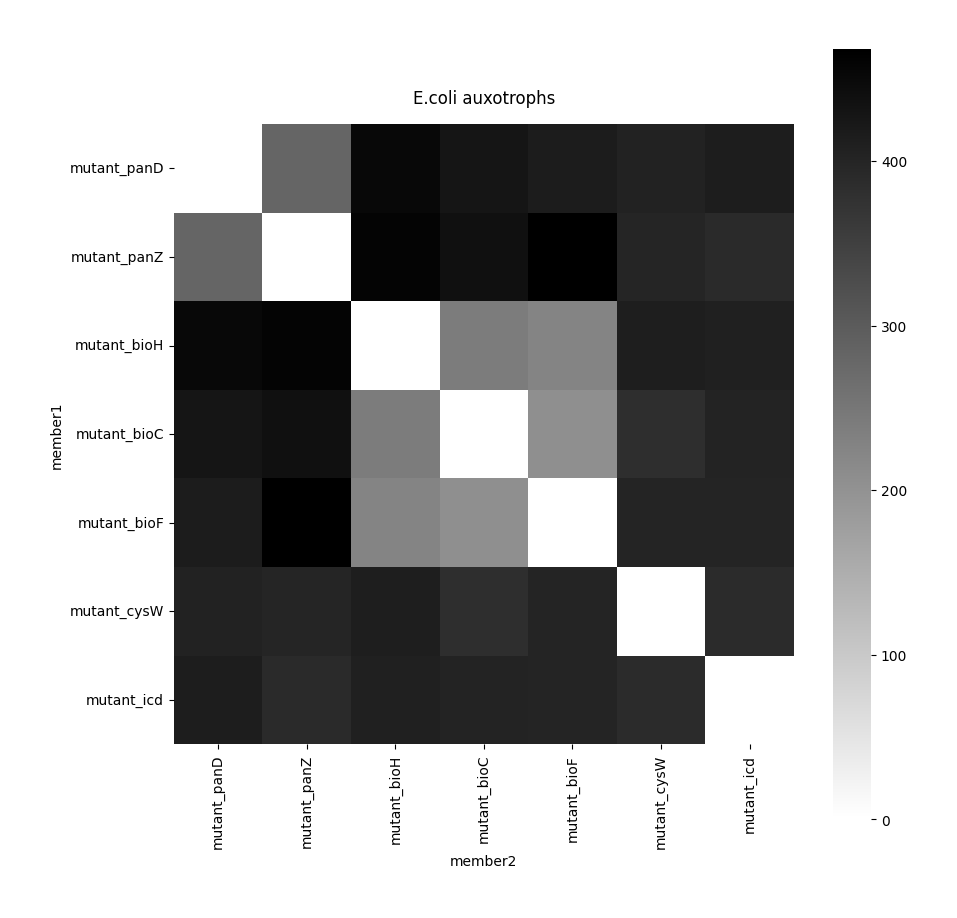

In [24]:
co_growth.plot_co_growth_count_guillen(steadiercom_abundance_df)

<Axes: xlabel='member'>

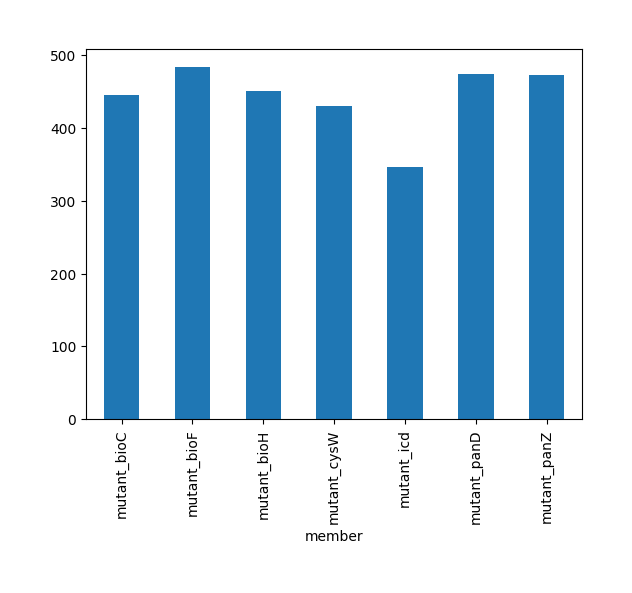

In [25]:
steadiercom_abundance_df.query("relative_abundance > 0.99").groupby("member")["relative_abundance"].count().plot(kind="bar")

In [26]:
co_growth_count_none,member_abund_df_none = co_growth.make_co_growth_count_matrix(steadiercom_abundance_df,"Ecoli_mutants")

[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.


<Axes: ylabel='member'>

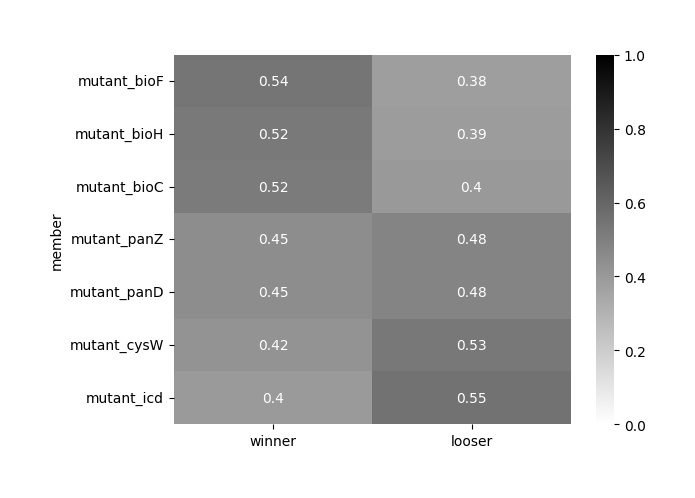

In [27]:
abundance_no_zeros = member_abund_df_none[member_abund_df_none>1e-6]
total_counts = abundance_no_zeros.count()

winner = abundance_no_zeros.eq(abundance_no_zeros.max(axis=1),axis=0).sum().sort_values()
winner = (winner/total_counts).sort_values()
winner.name="winner"

looser = abundance_no_zeros.eq(abundance_no_zeros.min(axis=1),axis=0).sum().sort_values()
looser = (looser/total_counts).sort_values()
looser.name="looser"

winner_looser = pd.concat([winner,looser],axis=1)
winner_looser = winner_looser.sort_values(by="winner",ascending=False)
sns.heatmap(winner_looser,cmap="binary",vmin=0,vmax=1,annot=True)

(0.0, 0.3)

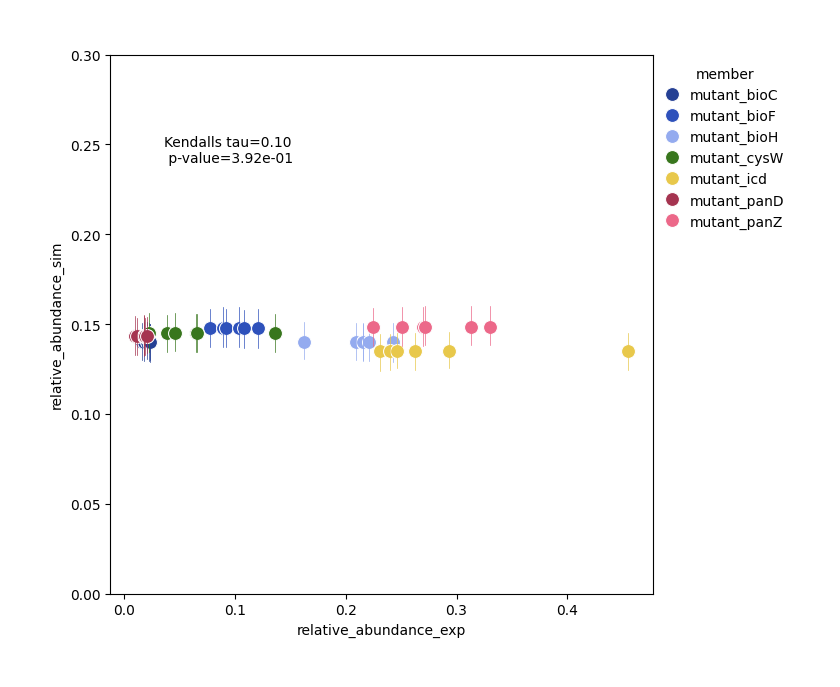

In [28]:
merged = pd.merge(steadiercom_abundance_df, exp_abundance_replicas, on=["member"], suffixes=("_sim","_exp"))
joined_mean = merged.groupby(["community_exp","member"]).agg({'relative_abundance_sim':'mean','relative_abundance_exp':'mean'})\
                        .rename(columns={'relative_abundance_sim':'SteadierCom relative abundance','relative_abundance_exp':'Experimental relative abundance'})

stat = kendalltau(joined_mean["Experimental relative abundance"],joined_mean["SteadierCom relative abundance"])

fig,ax = plt.subplots(figsize=(7,7))
ax = sns.lineplot(merged,
            x="relative_abundance_exp",
            y="relative_abundance_sim",
            hue="member",
            palette=member2color_dict,
            marker="o",
            markersize=10,
            linestyle="",
            err_style="bars",
            errorbar="ci",
            ax=ax
            )

sns.move_legend(ax, 
                "upper left",
                bbox_to_anchor=(1.0, 1.0)
                )

ax.text(0.1, 0.8, f"Kendalls tau={stat.correlation:.2f} \n p-value={stat.pvalue:.2e}", transform=ax.transAxes)
ax.set_ylim([0,0.3])